In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/Stata15/utilities")
# from pystata import config
# config.init()

In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [3]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [4]:
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'

train = df_part3.loc[train_start_date : train_end_date]
test = df_part3.loc[test_start_date:test_end_date]

In [5]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [6]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    print(date)
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

2021-06-01
2021-06-02
2021-06-03
2021-06-04
2021-06-07
2021-06-08
2021-06-09
2021-06-10
2021-06-11
2021-06-14
2021-06-15
2021-06-16
2021-06-17
2021-06-18
2021-06-21
2021-06-22
2021-06-23
2021-06-24
2021-06-25
2021-06-28
2021-06-29
2021-06-30
2021-07-01
2021-07-02
2021-07-06
2021-07-07
2021-07-08
2021-07-09
2021-07-12
2021-07-13
2021-07-14
2021-07-15


In [7]:
y_train = pd.DataFrame(train['vix'])
y_test = pd.DataFrame(test['vix'])

In [8]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
y_train = np.nan_to_num(y_train)
numpy_df_train = np.nan_to_num(numpy_df_train)
rf.fit(numpy_df_train, y_train)

RandomForestRegressor()

In [9]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

In [11]:
idx = y_test.index
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['predicted_vix'] )

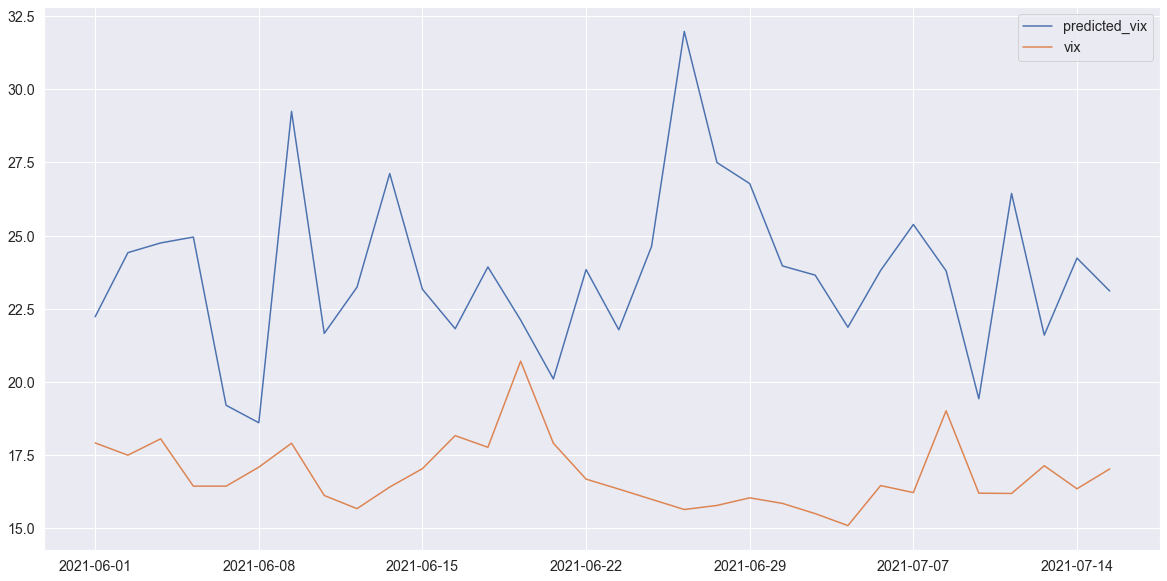

In [12]:
predictions_plot = predictions_df.plot()
fig = y_test.plot(ax = predictions_plot,figsize=(20,10)).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/random_forest_without_smoothing_sp500.png")
# matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

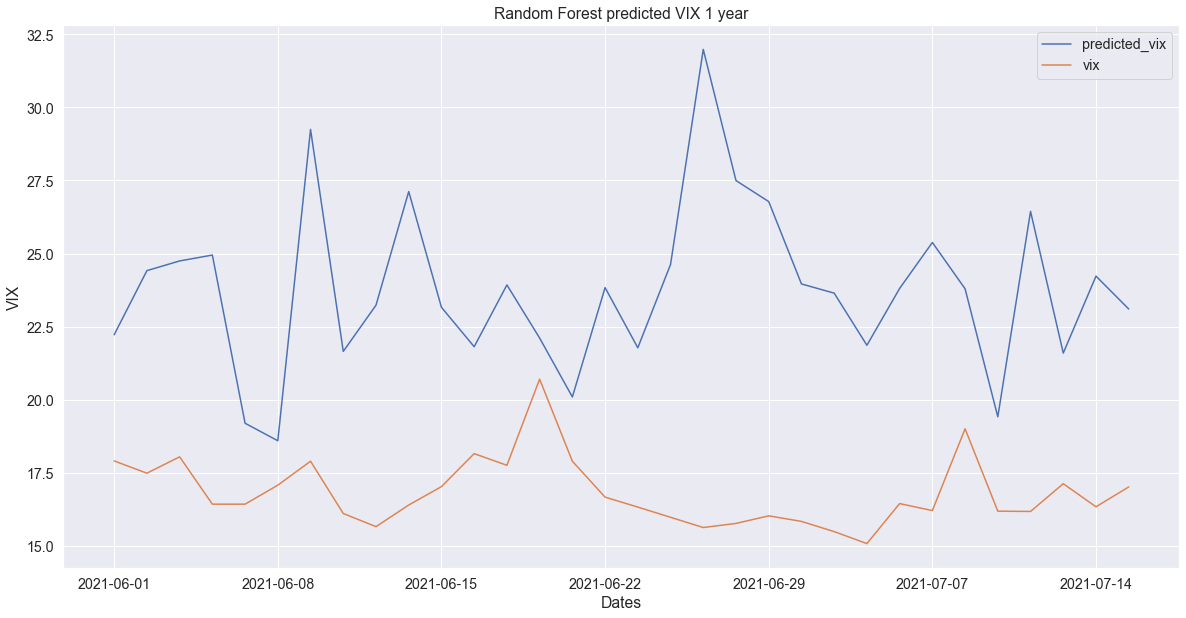

In [13]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax, figsize=(20,10)).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/random_forest_without_smoothing2_sp500.png")

# colors = ['332288', '88CCEE', '44AA99', '117733', '999933', 'DDCC77', 'CC6677', '882255', 'AA4499']

# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [14]:
from datetime import datetime, timedelta

temp_date = test_start_date
print(test_start_date)
print(datetime.astimezone)
average_last_5_days_test = 0
total_days = 10
print("type="+str(type(test.loc[temp_date, 'vix'])))
for i in range(total_days):
    number_to_add = test.loc[temp_date, 'vix']
    average_last_5_days_test += number_to_add
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Reducing one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print (temp_date)
average_last_5_days_test = average_last_5_days_test / total_days
print (average_last_5_days_test)

temp_date = test_start_date
average_upcoming_5_days_predicted = 0
for i in range(total_days):
    average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'vix']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Adding one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print(temp_date)
average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
print (average_upcoming_5_days_predicted)
#average train.loc['2013-12-31', 'VIX'] - advpredictions_df.loc['2014-01-01', 'VIX']
difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
print (difference_test_predicted_VIX)

2021-06-01
<method 'astimezone' of 'datetime.datetime' objects>
type=<class 'numpy.float64'>
2021-06-02
2021-06-03
2021-06-04
2021-06-05


KeyError: '2021-06-05'

In [ ]:
# Adding 6177 to all the advpredictions_df VIX values
predictions_df['vix'] = predictions_df['vix'] + difference_test_predicted_VIX

In [ ]:
ax = predictions_df.rename(columns={"vix": "predicted_VIX"}).plot(title='Random Forest after aligning')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"vix": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/random_forest_with_aligning_sp500.png")

# Smoothing the time series data

# Applying EWM pandas to smooth the VIX volatility

In [ ]:
predictions_df['ewm'] = predictions_df["vix"].ewm(span=60).mean()

In [ ]:
predictions_df['actual_value'] = test['vix']
predictions_df['actual_value_ewm'] = predictions_df["actual_value"].ewm(span=60).mean()

In [ ]:
# Changing column names
predictions_df.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']

In [ ]:
# Now plotting test predictions after smoothing
predictions_plot = predictions_df.plot(title='Random Forest predicted VIX 1 year after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/random_forest_after_smoothing_var_sp500.png")


In [ ]:
# Plotting just predict and actual average curves
predictions_df_average = predictions_df[['average_predicted_VIX', 'average_actual_VIX']]
predictions_plot = predictions_df_average.plot(title='Random Forest after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/random_forest_after_smoothing2_mean_sp500.png")

# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [ ]:
def offset_value(test_start_date, test, predictions_df):
    temp_date = test_start_date
    average_last_5_days_test = 0
    average_upcoming_5_days_predicted = 0
    total_days = 10
    for i in range(total_days):
        average_last_5_days_test += test.loc[temp_date, 'vix']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_last_5_days_test = average_last_5_days_test / total_days

    temp_date = test_start_date
    for i in range(total_days):
        average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'vix']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
    difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
    return difference_test_predicted_VIX

# LogisticRegression

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []

# Splitting the training and testing data
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date : test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
print("#1")
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
# Linear regression model
lr = LogisticRegression()
lr.fit(numpy_df_train, train['VIX'])

#   if len(np.sum(train['VIX'])) in [len(train['VIX']),0]:
#       print ("all one class")
#       #do something else
#   else:
#       #OK to proceed
#       lenreg.fit(numpy_df_train, train['VIX'])
#       y_pred = lenreg.predict(numpy_df_train)
#       print (metics.accuracy_score(y_test, y_pred))


prediction = lr.predict(numpy_df_test)
prediction_list.append(prediction)
print (train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date)
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['vix'] = predictions_df_list['vix'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["vix"].ewm(span=10).mean()
predictions_df_list['actual_value'] = test['vix']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.set_ylabel("VIX")

predictions_df_list_average.plot(title='LogisticRegression', xlabel="Dates", ylabel="VIX")
# predictions_df_list.show()


In [ ]:
#TEMP
# Columns to plot 
plot_columns = ['sentiment','vix', "pos"]

# plot
fig, axes = plt.subplots(2,2,figsize=(25,15))
for i,col in enumerate(plot_columns):
    print("i="+str(i))
    print("col="+str(col))

    sns.regplot(col,'vix',data=train, ax=axes[i,0]) # regression plot
    sns.kdeplot(train[col],train['vix'],shade=True, ax=axes[i,1]) # kernel density estimate plot

In [ ]:
# Correlation matrix
corr = train[plot_columns].corr()

mask = np.zeros_like(corr)
for i in range(mask.shape[0]):
    mask[i,i]=True
plt.figure(figsize=(12,5))
sns.heatmap(corr,annot=True,mask=mask,cmap='coolwarm',vmin=-1,vmax=1)
plt.show()

In [ ]:
# Plot variables with high correlation coefficient

def cor_reg_kde(x,y,data):
    # Correlation coefficient
    print('correlation coefficient:',corr.loc[x,y])
    
    # Subplot adjust
    plt.subplots_adjust(wspace=0.5)
    
    # Plot (regression and kernel density)
    fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
    sns.regplot(x,y,data=data,ax=ax1)
    sns.kdeplot(data[x],data[y],shade=True,ax=ax2)
    
cor_reg_kde('sentiment','vix',train)
# cor_reg_kde('Indiv_Put_Netbuying_Quantity','Open_interest',train_org)
# cor_reg_kde('Indiv_Put_Netbuying_Quantity','Indiv_Call_Netbuying_Quantity',train_org)
# cor_reg_kde('Indiv_Call_Netbuying_Quantity','Open_interest',train_org)


In [ ]:
lr.classes_

In [ ]:
lr.coef_[0]

# RandomForestRegressor

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot(title='RandomForestRegressor', xlabel="Dates", ylabel="VIX")

#     predictions_df_list.show()


In [ ]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

In [ ]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot(title='MLP Classifier', xlabel="Dates", ylabel="VIX")

#     predictions_df_list.show()
    

In [ ]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

In [ ]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()

In [ ]:
#https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima_model.ARMAResults.plot_predict.html
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd

# dta = sm.datasets.sunspots.load_pandas().data[['SUNACTIVITY']]
# dta.index = pd.date_range(start='1700', end='2009', freq='A')
# print(type(dta))
# print(dta)
dta=df_part3["VIX"]
dta2=df_part3["sentiment"]
res = sm.tsa.ARMA(dta, (3, 0)).fit()
fig, ax = plt.subplots()
ax = dta.loc['2020-06-01':].plot(ax=ax)
fig = res.plot_predict('2021-07-15', '2021-08-15', dynamic=True, ax=ax,
                        plot_insample=False)
plt.title("ARMA")
plt.show()

In [ ]:
# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = df_part3["sentiment"].tolist()
# data = list(df_part3["sentiment","VIX"])

# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)

# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)


In [ ]:

# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)
print(yhat)
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)
print(yhat)